<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_harmoscill.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc
!pip install qiskit-bosons

  Using cached qiskit_bosons-0.1.0a1-cp311-abi3-manylinux_2_28_x86_64.whl.metadata (7.5 kB)
Using cached qiskit_bosons-0.1.0a1-cp311-abi3-manylinux_2_28_x86_64.whl (800 kB)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator,Pauli
from scipy.linalg import expm, svd
from qiskit_bosons.operators import BosonOperator, ann, cre
from qiskit_bosons.mappers import LevelSpec
from qiskit_bosons.mappers.library import occupation_encoding
from qiskit.quantum_info import SparsePauliOp
from scipy.linalg import expm, svd


drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
def sz_nonoise_harmonicosc_long(simulator_aer,alpha=0, N = 25, g = 0.7, l= 0.2,delta_t = 0.5,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024):
  p_zxz = Pauli('ZXZ').to_matrix()
  p_xzz = Pauli('XZZ').to_matrix()


  U21 =expm(1j*l/2*delta_t*(1-np.sqrt(3))*p_zxz)
  U22 = expm(-1j*l/2*delta_t*(np.sqrt(2))*p_xzz)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sz_2_nonoise = []

  for niter in range(0,N+1):
    qc = QuantumCircuit(4,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    #qc.ry(alpha,3)
    #qc.cx(3,4)
    for i in range(0,niter):
      qc.rzz(-omegah*delta_t,1,2)
      qc.rz(-omegah*2*delta_t,2)

      qc.rz(-omega_A*delta_t,3)

      qc.rxx(g*delta_t,0,3)
      qc.ryy(g*delta_t,0,3)

      qc.rzx(-l*delta_t*(1+np.sqrt(3)),0,1)
      qc.rzx(-l*delta_t*(np.sqrt(2)),0,2)
      qc.append(U21_gate, [0,1,2])
      qc.append(U22_gate, [0,1,2])

      qc.rz(-omega*delta_t,0)

      qc.reset(3)
      #qc.reset(4)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [5]:
def sx_nonoise_harmonicosc_long(simulator_aer,alpha=0, N = 25, g = 0.7, l= 0.2,delta_t = 0.5,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024):
  p_zxz = Pauli('ZXZ').to_matrix()
  p_xzz = Pauli('XZZ').to_matrix()


  U21 =expm(1j*l/2*delta_t*(1-np.sqrt(3))*p_zxz)
  U22 = expm(-1j*l/2*delta_t*(np.sqrt(2))*p_xzz)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sx_2_nonoise = []

  for niter in range(0,N+1):
    qc = QuantumCircuit(4,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    #qc.ry(alpha,3)
    #qc.cx(3,4)
    for i in range(0,niter):
      qc.rzz(-omegah*delta_t,1,2)
      qc.rz(-omegah*2*delta_t,2)

      qc.rz(-omega_A*delta_t,3)

      qc.rxx(g*delta_t,0,3)
      qc.ryy(g*delta_t,0,3)

      qc.rzx(-l*delta_t*(1+np.sqrt(3)),0,1)
      qc.rzx(-l*delta_t*(np.sqrt(2)),0,2)
      qc.append(U21_gate, [0,1,2])
      qc.append(U22_gate, [0,1,2])

      qc.rz(-omega*delta_t,0)

      qc.reset(3)
      #qc.reset(4)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [6]:
def sy_nonoise_harmonicosc_long(simulator_aer,alpha=0, N = 25, g = 0.7, l= 0.2,delta_t = 0.5,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024):
  p_zxz = Pauli('ZXZ').to_matrix()
  p_xzz = Pauli('XZZ').to_matrix()


  U21 =expm(1j*l/2*delta_t*(1-np.sqrt(3))*p_zxz)
  U22 = expm(-1j*l/2*delta_t*(np.sqrt(2))*p_xzz)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sy_2_nonoise = []

  for niter in range(0,N+1):
    qc = QuantumCircuit(4,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    #qc.ry(alpha,3)
    #qc.cx(3,4)
    for i in range(0,niter):
      qc.rzz(-omegah*delta_t,1,2)
      qc.rz(-omegah*2*delta_t,2)

      qc.rz(-omega_A*delta_t,3)

      qc.rxx(g*delta_t,0,3)
      qc.ryy(g*delta_t,0,3)

      qc.rzx(-l*delta_t*(1+np.sqrt(3)),0,1)
      qc.rzx(-l*delta_t*(np.sqrt(2)),0,2)
      qc.append(U21_gate, [0,1,2])
      qc.append(U22_gate, [0,1,2])

      qc.rz(-omega*delta_t,0)

      qc.reset(3)
      #qc.reset(4)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sy_2_nonoise.append(-valor)
  return sy_2_nonoise

In [45]:
def sz_nonoise_harmonicosc_trans(simulator_aer, N = 25, g = 0.7, l= 0.2,delta_t = 0.5, T = 0,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024, bosonic = False):
  p_zxx = Pauli('ZXX').to_matrix()
  p_xzx = Pauli('XZX').to_matrix()


  U21 =expm(-1j*l/2*delta_t*(1-np.sqrt(3))*p_zxx)
  U22 = expm(1j*l/2*delta_t*(np.sqrt(2))*p_xzx)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sz_2_nonoise = []




  if T !=0:
    beta = 1/T
    alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
    if bosonic==True:
      n_B = 1/(np.exp(omega_A/T)-1)
      g = g*np.sqrt(2*n_B+ 1)
    for niter in range(0,N+1):
      qc = QuantumCircuit(5,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      qc.ry(alpha,3)
      qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        qc.reset(4)
        qc.ry(alpha,3)
        qc.cx(3,4)
      qc.measure(0,0)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_nonoise.append(-valor)
  else:
    for niter in range(0,N+1):
      qc = QuantumCircuit(4,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        #qc.reset(4)
        #qc.ry(alpha,3)
        #qc.cx(3,4)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [46]:
def sx_nonoise_harmonicosc_trans(simulator_aer, N = 25, g = 0.7, l= 0.2,delta_t = 0.5, T=0,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024,bosonic = False):
  p_zxx = Pauli('ZXX').to_matrix()
  p_xzx = Pauli('XZX').to_matrix()


  U21 =expm(-1j*l/2*delta_t*(1-np.sqrt(3))*p_zxx)
  U22 = expm(1j*l/2*delta_t*(np.sqrt(2))*p_xzx)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sx_2_nonoise = []


  if T !=0:
    beta = 1/T
    alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
    if bosonic==True:
      n_B = 1/(np.exp(omega_A/T)-1)
      g = g*np.sqrt(2*n_B+ 1)

    for niter in range(0,N+1):
      qc = QuantumCircuit(5,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      qc.ry(alpha,3)
      qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        qc.reset(4)
        qc.ry(alpha,3)
        qc.cx(3,4)
      qc.h(0)
      qc.measure(0,0)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sx_2_nonoise.append(valor)
  else:
    for niter in range(0,N+1):
      qc = QuantumCircuit(4,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        #qc.reset(4)
        #qc.ry(alpha,3)
        #qc.cx(3,4)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [47]:
def sy_nonoise_harmonicosc_trans(simulator_aer,alpha=0, N = 25, g = 0.7, l= 0.2,delta_t = 0.5,T=0,omega = 0.5, omega_A = 0.5, omegah = 0.5, nshots = 1024,bosonic = False):
  p_zxx = Pauli('ZXX').to_matrix()
  p_xzx = Pauli('XZX').to_matrix()


  U21 =expm(-1j*l/2*delta_t*(1-np.sqrt(3))*p_zxx)
  U22 = expm(-
             1j*l/2*delta_t*(np.sqrt(2))*p_xzx)
  U21_gate = UnitaryGate(U21, label="U21")
  U22_gate = UnitaryGate(U22, label="U22")


  sy_2_nonoise = []



  if T !=0:
    beta = 1/T
    alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
    if bosonic==True:
      n_B = 1/(np.exp(omega_A/T)-1)
      g = g*np.sqrt(2*n_B+ 1)

    for niter in range(0,N+1):
      qc = QuantumCircuit(5,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        #qc.reset(4)
        #qc.ry(alpha,3)
        #qc.cx(3,4)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sy_2_nonoise.append(-valor)
  else:
    for niter in range(0,N+1):
      qc = QuantumCircuit(4,1)
      qc.ry(np.pi-np.pi/3,0)
      qc.rz(-np.pi/3,0)
      #qc.ry(alpha,3)
      #qc.cx(3,4)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,1,2)
        qc.rz(-omegah*2*delta_t,2)

        qc.rz(-omega_A*delta_t,3)

        qc.rxx(g*delta_t,0,3)
        qc.ryy(g*delta_t,0,3)

        qc.rxx(l*delta_t*(1+np.sqrt(3)),0,1)
        qc.rxx(l*delta_t*(np.sqrt(2)),0,2)
        qc.append(U21_gate, [0,1,2])
        qc.append(U22_gate, [0,1,2])

        qc.rz(-omega*delta_t,0)

        qc.reset(3)
        #qc.reset(4)
        #qc.ry(alpha,3)
        #qc.cx(3,4)
      qc.sdg(0)
      qc.h(0)
      qc.measure(0,0)

      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
      sy_2_nonoise.append(-valor)
  return sy_2_nonoise

0 0
0 0.1
0 0.5
0 1


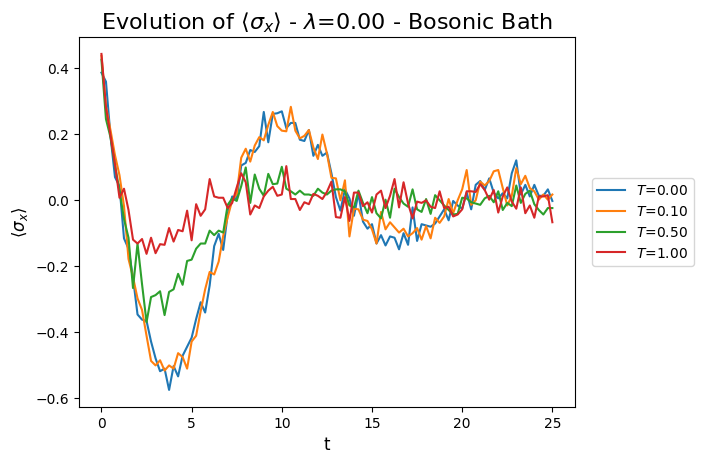

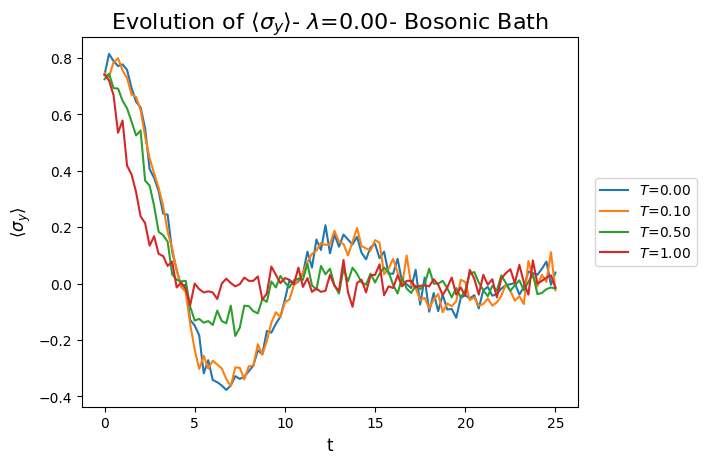

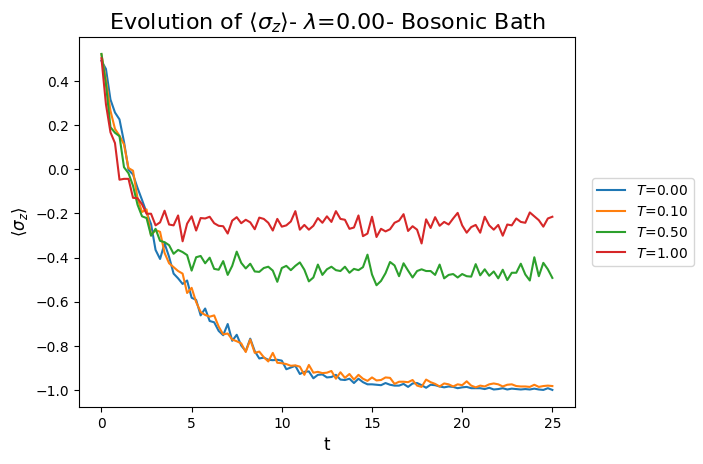

0.1 0
0.1 0.1
0.1 0.5
0.1 1


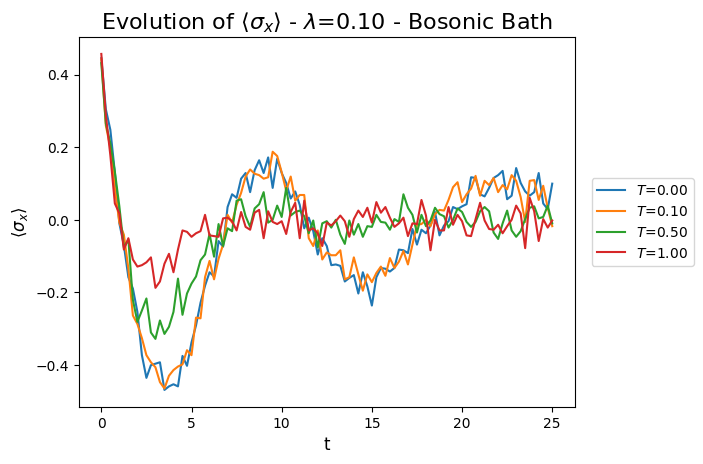

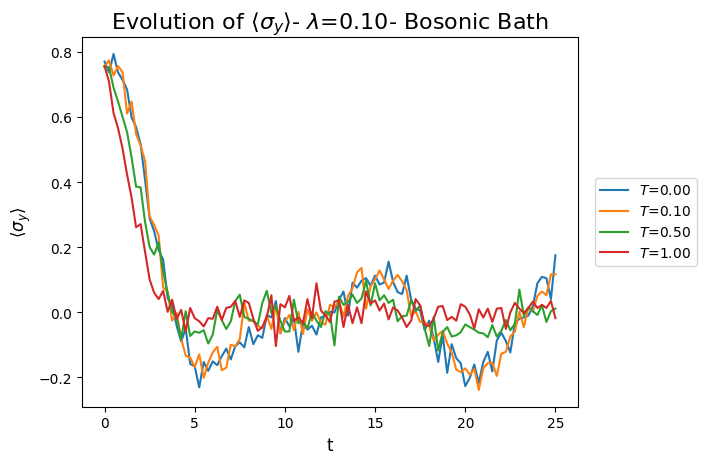

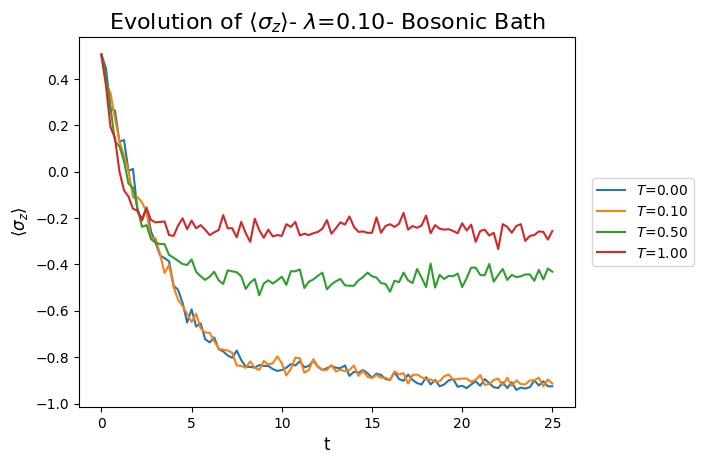

0.5 0
0.5 0.1
0.5 0.5
0.5 1


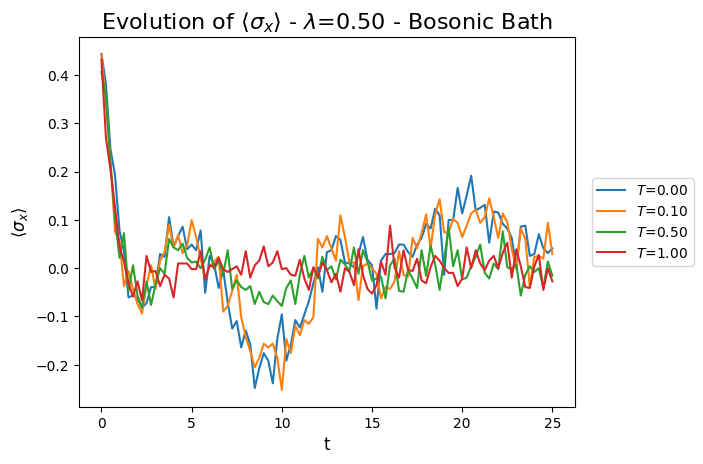

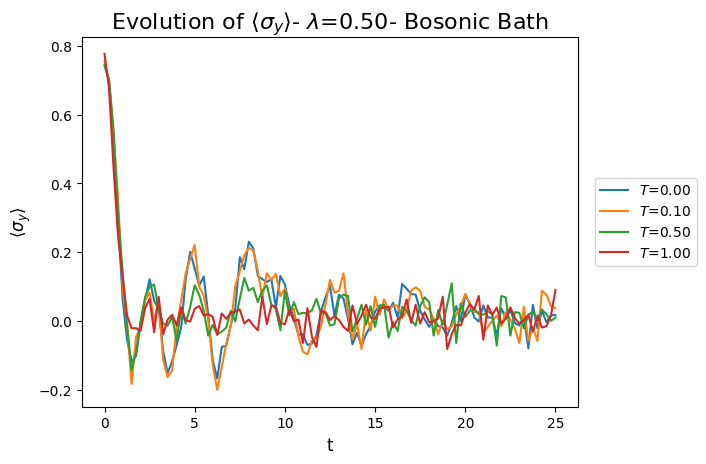

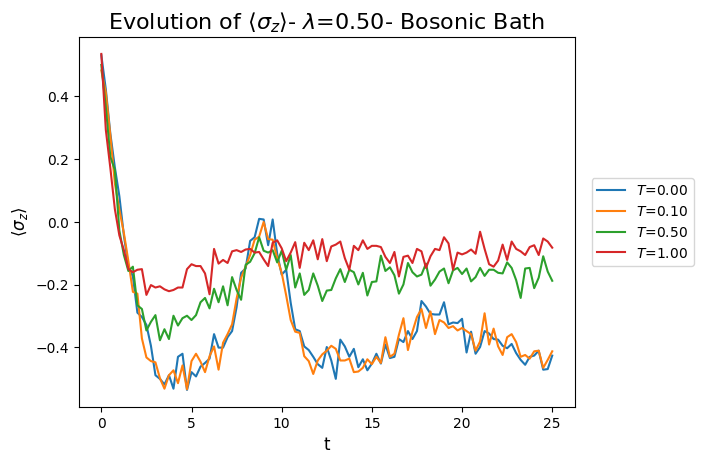

1 0
1 0.1
1 0.5
1 1


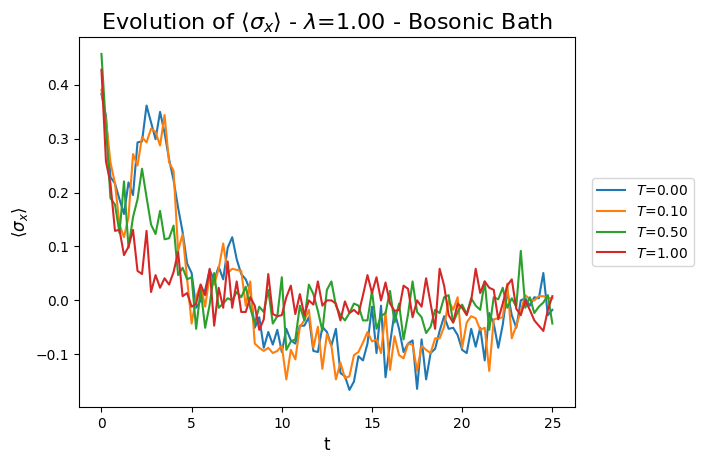

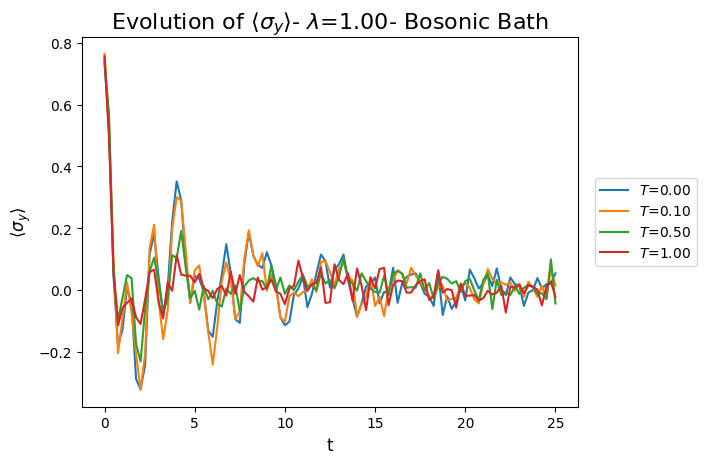

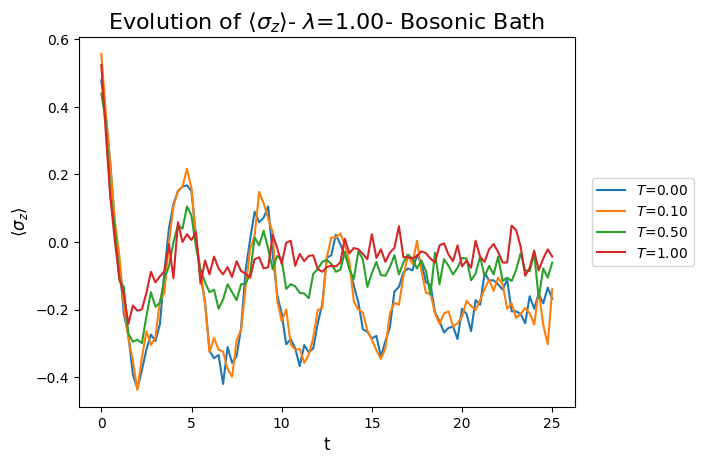

In [49]:
simulator_aer = AerSimulator()
Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
omega = 0.5
N = int(25/delta_t)
omega_A = omega
nshots = 1024
omegah = 0.25
time = np.arange(N+1) * delta_t

for l in [0,0.1,0.5,1]:
  fig_x, ax_x = plt.subplots()
  fig_y, ax_y = plt.subplots()
  fig_z, ax_z = plt.subplots()
  for T in [0,0.1,0.5,1]:
    print(l,T)
    #sz = sz_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
    #sx = sx_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
    #sy = sy_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)

    sz = sz_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)
    sx = sx_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)
    sy = sy_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t,T=T, omega = omega, omega_A=omega_A, omegah=omegah,bosonic = True)


    ax_x.plot(time, sx, label=rf'$T$={T:.2f}')
    ax_y.plot(time, sy, label=rf'$T$={T:.2f}')
    ax_z.plot(time, sz, label=rf'$T$={T:.2f}')

    datos = np.column_stack((time, sx,sy,sz))

    np.savetxt(
    f"/content/drive/MyDrive/qiskit_harmosc_trans_bosonicbath_ns1024_nonoise_l_{l:.2f}_omega_{omega:.2f}_omegah_{omegah:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt",
    datos,
    header="t sx sy sz",
    fmt="%.10f"
    )



  ax_x.set_xlabel('t', fontsize = 12)
  ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
  ax_x.set_title(rf'Evolution of $\langle \sigma_x \rangle$ - $\lambda$={l:.2f} - Bosonic Bath', fontsize = 16)
  ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

  ax_y.set_xlabel('t', fontsize = 12)
  ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize = 12)
  ax_y.set_title(rf'Evolution of $\langle \sigma_y \rangle$- $\lambda$={l:.2f}- Bosonic Bath', fontsize = 16)
  ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

  ax_z.set_xlabel('t', fontsize = 12)
  ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize = 12)
  ax_z.set_title(rf'Evolution of $\langle \sigma_z \rangle$- $\lambda$={l:.2f}- Bosonic Bath', fontsize = 16)
  ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
  plt.show()

  #plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
  #plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
  #plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

  #plt.xlabel('t')
  #plt.ylabel('Expected Value')
  #plt.legend()


KeyboardInterrupt: 

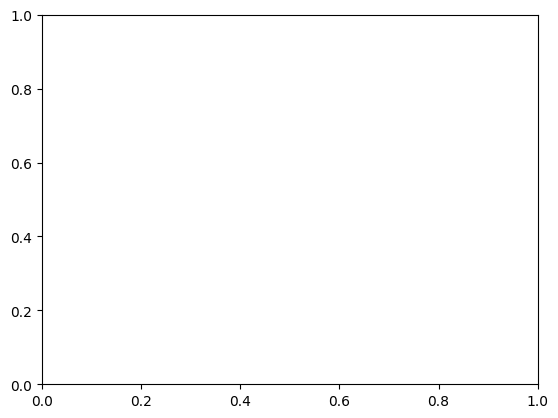

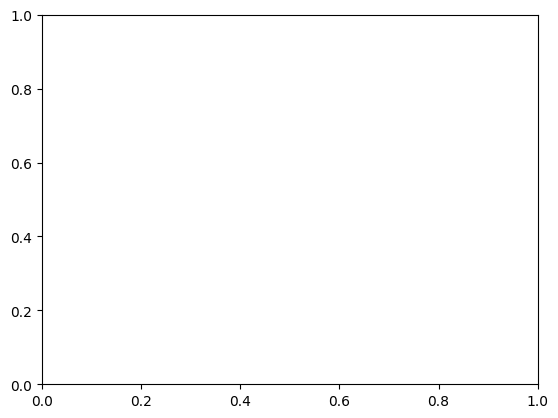

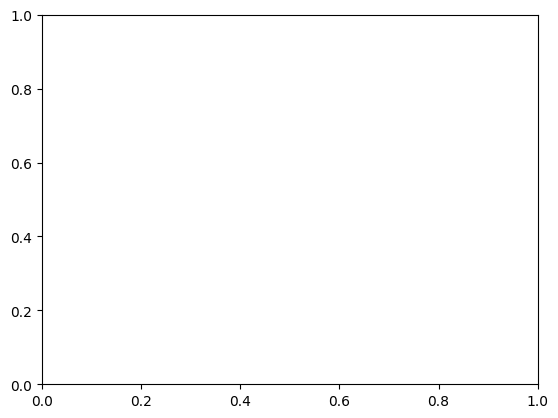

In [15]:
simulator_aer = AerSimulator()
fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()
T=0
simulator_aer = AerSimulator()
Gamma = 0.25
delta_t = 0.1
g = np.sqrt(Gamma/delta_t)
omega = 0.5
N = int(25/delta_t)
omega_A = omega
nshots = 1024
omegah = 0.25
time = np.arange(N+1) * delta_t

for l in [0,0.1,0.5,1]:
  #sz = sz_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
  #sx = sx_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
  #sy = sy_nonoise_harmonicosc(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)

  sz = sz_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
  sx = sx_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)
  sy = sy_nonoise_harmonicosc_trans(simulator_aer= simulator_aer, l = l, g=g, N = N, delta_t = delta_t, omega = omega, omega_A=omega_A, omegah=omegah)


  ax_x.plot(time, sx, label=rf'$\lambda$={l:.2f}')
  ax_y.plot(time, sy, label=rf'$\lambda$={l:.2f}')
  ax_z.plot(time, sz, label=rf'$\lambda$={l:.2f}')

  datos = np.column_stack((time, sx,sy,sz))

  np.savetxt(
  f"/content/drive/MyDrive/qiskit_harmosc_trans_ns1024_nonoise_l_{l:.2f}_omega_{omega:.2f}_omegah_{omegah:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )



ax_x.set_xlabel('t', fontsize = 12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ ', fontsize = 16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

# Configurar figura de Y
ax_y.set_xlabel('t', fontsize = 12)
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize = 12)
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$', fontsize = 16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

# Configurar figura de Z
ax_z.set_xlabel('t', fontsize = 12)
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize = 12)
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$', fontsize = 16)
ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.show()

#plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
#plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
#plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

#plt.xlabel('t')
#plt.ylabel('Expected Value')
#plt.legend()


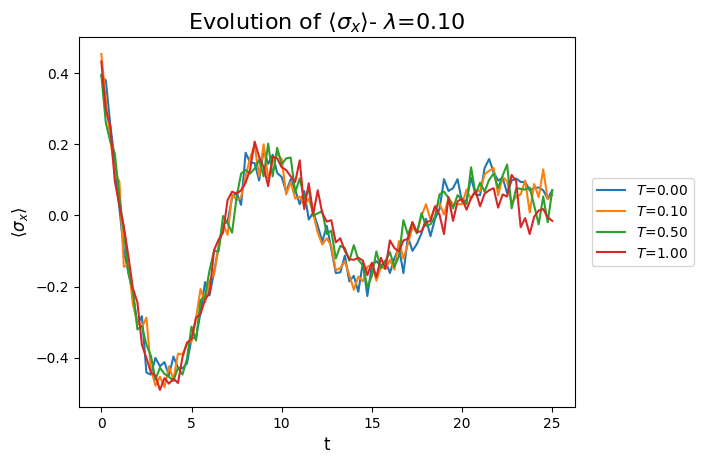

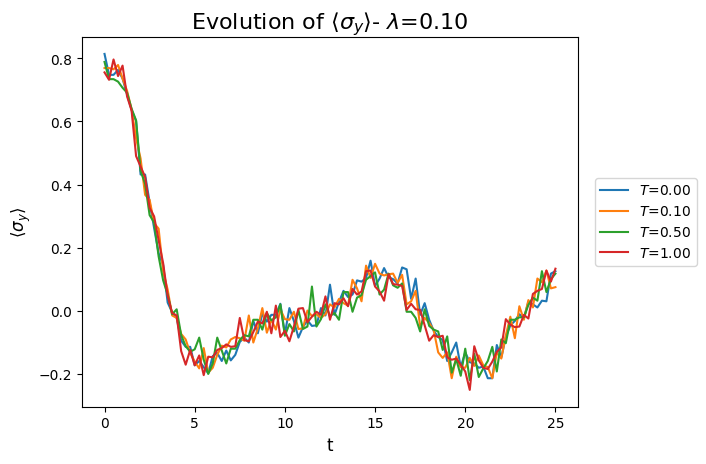

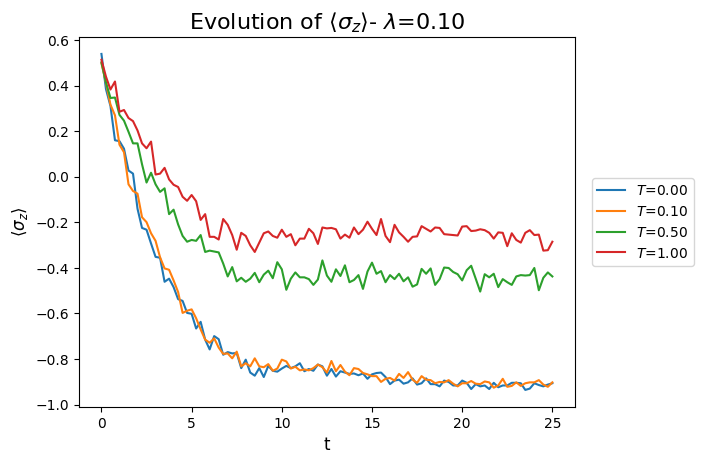

In [55]:

omega = 0.5
omegah = 0.25
delta_t = 0.25
T = 0

l_values = [0.1, 0.5, 1]

fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()

for l in l_values:
  for T in [0,0.1,0.5,1]:

    filename = (
        f"/content/drive/MyDrive/"
        f"qiskit_harmosc_trans_ns1024_nonoise_"
        f"l_{l:.2f}_omega_{omega:.2f}_"
        f"omegah_{omegah:.2f}_"
        f"deltat_{delta_t:.2f}_T_{T:.2f}.txt"
    )

    datos = np.loadtxt(filename, skiprows=1)

    time = datos[:, 0]
    sx = datos[:, 1]
    sy = datos[:, 2]
    sz = datos[:, 3]

    ax_x.plot(time, sx, label=rf'$T$={T:.2f}')
    ax_y.plot(time, sy, label=rf'$T$={T:.2f}')
    ax_z.plot(time, sz, label=rf'$T$={T:.2f}')


  ax_x.set_xlabel('t', fontsize=12)
  ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize=12)
  ax_x.set_title(rf'Evolution of $\langle \sigma_x \rangle$- $\lambda$={l:.2f}', fontsize = 16)
  ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


  ax_y.set_xlabel('t', fontsize=12)
  ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize=12)
  ax_y.set_title(rf'Evolution of $\langle \sigma_y \rangle$- $\lambda$={l:.2f}', fontsize = 16)
  ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


  ax_z.set_xlabel('t', fontsize=12)
  ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize=12)
  ax_z.set_title(rf'Evolution of $\langle \sigma_z \rangle$- $\lambda$={l:.2f}', fontsize = 16)
  ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

  plt.show()

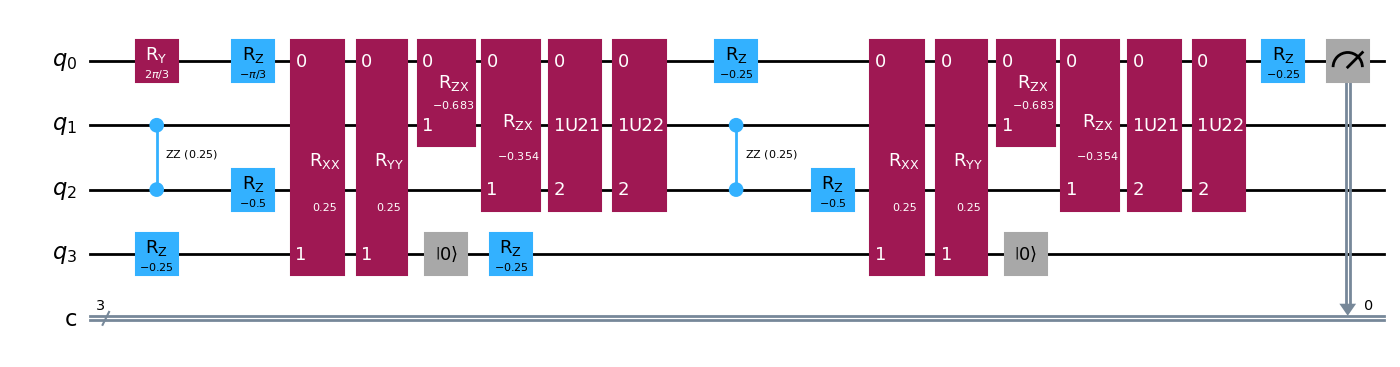

In [51]:

l=delta_t=omega = omegah = omega_A =g= 0.5
p_zxz = Pauli('ZXZ').to_matrix()
p_xzz = Pauli('XZZ').to_matrix()


U21 =expm(1j*l/2*delta_t*(1-np.sqrt(3))*p_zxz)
U22 = expm(-1j*l/2*delta_t*(np.sqrt(2))*p_xzz)
U21_gate = UnitaryGate(U21, label="U21")
U22_gate = UnitaryGate(U22, label="U22")


sz_2_nonoise = []


qc = QuantumCircuit(4,3)
qc.ry(np.pi-np.pi/3,0)
qc.rz(-np.pi/3,0)
#qc.ry(alpha,3)
#qc.cx(3,4)
for i in range(0,2):
  qc.rzz(omegah*delta_t,1,2)
  qc.rz(-omegah*2*delta_t,2)

  qc.rz(-omega_A*delta_t,3)

  qc.rxx(g*delta_t,0,3)
  qc.ryy(g*delta_t,0,3)

  qc.rzx(-l*delta_t*(1+np.sqrt(3)),0,1)
  qc.rzx(-l*delta_t*(np.sqrt(2)),0,2)
  qc.append(U21_gate, ([0,1,2]))
  qc.append(U22_gate, [0,1,2])

  qc.rz(-omega*delta_t,0)

  qc.reset(3)
  #qc.reset(4)
  #qc.ry(alpha,3)
  #qc.cx(3,4)
qc.measure(0,0)
qc.draw('mpl')